## K-Means Clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("penguins.csv")
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

df = df.dropna(subset=features)
X_raw = df[features].to_numpy()
species = df["species"].to_numpy()
print(X_raw.shape)



(342, 4)


The dataset has 344 penguins, but 2 rows had all measurements missing, so they were removed. We are left with 342 penguins.

In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
print(X.mean(axis=0).round(3), X.std(axis=0).round(3))


[ 0.  0. -0.  0.] [1. 1. 1. 1.]


In [3]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3, n_init=10, random_state=0)
labels = km.fit_predict(X)

print(labels[:10])
print("Inertia:", km.inertia_)
print("Iterations:", km.n_iter_)

[0 0 0 0 0 0 0 0 2 0]
Inertia: 379.39250275551757
Iterations: 6


K-means split the penguins into 3 clusters, numbered 0, 1 and 2. These numbers are just names, not species.

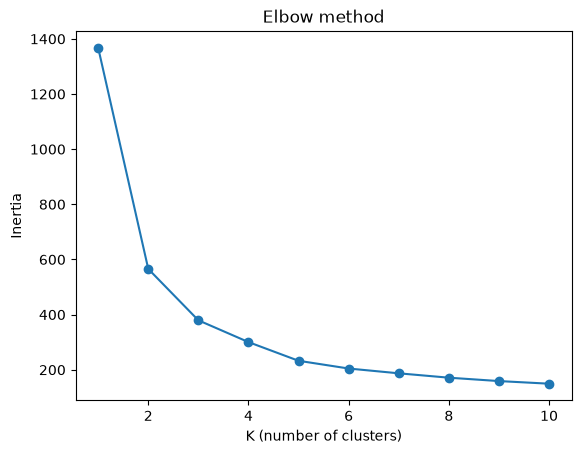

In [4]:
ks = range(1,11)
inertias = []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertias.append(km_k.inertia_)

plt.plot(ks, inertias, marker="o")
plt.xlabel("K (number of clusters)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

Inertia always goes down as k increases, because more clusters means every point is closer to a centre.

In [5]:
print(pd.crosstab(species,labels, rownames=["Species"], colnames=["Clusters"]))

Clusters     0    1   2
Species                
Adelie     127    0  24
Chinstrap    5    0  63
Gentoo       0  123   0



- The table shows which cluster each species ended up in.
- 313 out of 342 penguins (about 91%) are in the cluster that matches their species. All the mistakes are between Adelie and Chinstrap.

In [6]:
from sklearn.metrics import adjusted_rand_score, silhouette_score

print("Adjusted Rand Index:", adjusted_rand_score(species, labels))
print("Silhouette:", silhouette_score(X, labels))

Adjusted Rand Index: 0.7928369051321087
Silhouette: 0.44721929839660457


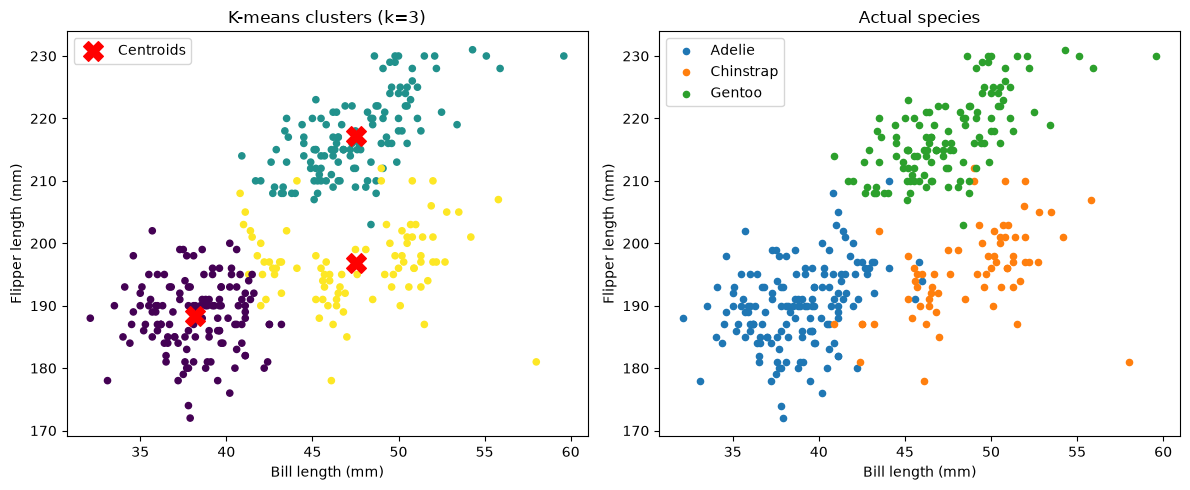

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_raw[:,0], X_raw[:,2], c=labels, cmap="viridis", s=20)
centroids = scaler.inverse_transform(km.cluster_centers_)
axes[0].scatter(centroids[:,0], centroids[:,2], c="red", marker="X", s=200, label="Centroids")
axes[0].set_xlabel("Bill length (mm)")
axes[0].set_ylabel("Flipper length (mm)")
axes[0].set_title("K-means clusters (k=3)")
axes[0].legend()

for sp in np.unique(species):
    mask = species == sp
    axes[1].scatter(X_raw[mask, 0], X_raw[mask, 2], label=sp, s=20)

axes[1].set_xlabel("Bill length (mm)")
axes[1].set_ylabel("Flipper length (mm)")
axes[1].set_title("Actual species")
axes[1].legend()

plt.tight_layout()
plt.show()

# CONCLUSION
- K-means found the 3 penguin species quite well using only body measurements, without ever seeing the species labels (about 91% match, ARI = 0.79).
- It works best when groups are clearly different, like Gentoo, which were grouped perfectly.
- It makes mistakes when groups overlap, like Adelie and Chinstrap, which mainly differ only in bill length.
